<a href="https://colab.research.google.com/github/CharalapML/ColabCode/blob/main/3D_Earthquake_clustering1_USGSdatafromSEAsia_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

# utm is not preinstalled in Colab; locally it is installed from requirements.txt
if 'google.colab' in sys.modules:
    %pip install -q utm


In [2]:
import numpy as np
import pandas as pd
import utm
import matplotlib.pyplot as plt
%matplotlib inline
from mpl_toolkits.mplot3d import axes3d

from sklearn.cluster import KMeans
from sklearn.preprocessing import Normalizer

import plotly.express as px
from plotly.express import scatter_3d
import plotly.graph_objs as go

import plotly.io as pio


**The followinbg data was downloaded from the USGS survey data it covers an area across SE Asia from about 2016 to 2026 and is for Earthquake greater than magnitude 5.5 **

In [3]:
from pathlib import Path

# Use the CSV bundled with the repo; fall back to the GitHub copy when the notebook is opened on its own (e.g. in Colab)
DATA_PATH = Path('data/EarthQuakeData_SE_Asia.csv')
DATA_URL = 'https://raw.githubusercontent.com/CharalapML/ColabCode/main/data/EarthQuakeData_SE_Asia.csv'
df = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)


In [4]:
df.head(5)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,2026-10-22T15:37:40.678Z,"126 km S of Kokopo, Papua New Guinea",earthquake,5.94,4.617,0.043,52.0,reviewed,us,us
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,2026-10-18T06:07:28.300Z,"13 km SW of Burias, Philippines",earthquake,9.03,5.696,0.068,21.0,reviewed,us,us
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,2026-10-05T18:25:35.012Z,"39 km WSW of Tambolaka, Indonesia",earthquake,9.53,6.808,0.062,25.0,reviewed,us,us
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,2026-09-29T14:45:36.205Z,"72 km ESE of Kokopo, Papua New Guinea",earthquake,20.25,7.054,0.051,37.0,reviewed,us,us
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,2026-10-12T16:49:37.977Z,"50 km NNE of Kainantu, Papua New Guinea",earthquake,7.35,1.936,0.039,62.0,reviewed,us,us


In [5]:
print (df[df.mag >= 4].count() )

time               689
latitude           689
longitude          689
depth              689
mag                689
magType            689
nst                303
gap                689
dmin               689
rms                689
net                689
id                 689
updated            689
place              689
type               689
horizontalError    689
depthError         689
magError           668
magNst             668
status             689
locationSource     689
magSource          689
dtype: int64


We'll use the 'quakes' dataset, what is it?  Read the documentation to find out:

In [6]:
type(df)
display (df)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,2026-10-22T15:37:40.678Z,"126 km S of Kokopo, Papua New Guinea",earthquake,5.94,4.617,0.043,52.0,reviewed,us,us
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,2026-10-18T06:07:28.300Z,"13 km SW of Burias, Philippines",earthquake,9.03,5.696,0.068,21.0,reviewed,us,us
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,2026-10-05T18:25:35.012Z,"39 km WSW of Tambolaka, Indonesia",earthquake,9.53,6.808,0.062,25.0,reviewed,us,us
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,2026-09-29T14:45:36.205Z,"72 km ESE of Kokopo, Papua New Guinea",earthquake,20.25,7.054,0.051,37.0,reviewed,us,us
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,2026-10-12T16:49:37.977Z,"50 km NNE of Kainantu, Papua New Guinea",earthquake,7.35,1.936,0.039,62.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
684,2016-11-09T14:50:59.680Z,-4.7403,149.8713,448.760,5.9,mww,NaN,23,2.190,0.77,...,2022-05-03T19:46:58.624Z,"94 km NNW of Kimbe, Papua New Guinea",earthquake,8.80,3.700,NaN,NaN,reviewed,us,us
685,2016-11-01T19:03:30.100Z,-6.1039,148.6588,51.990,6.0,mww,NaN,17,3.600,0.82,...,2022-05-03T19:46:33.484Z,"99 km W of Kandrian, Papua New Guinea",earthquake,6.70,4.100,NaN,NaN,reviewed,us,us
686,2016-10-28T05:26:55.910Z,-4.6721,153.2156,45.150,5.9,mww,NaN,26,1.152,0.92,...,2022-05-03T18:56:11.758Z,"111 km ESE of Kokopo, Papua New Guinea",earthquake,6.20,4.400,NaN,NaN,reviewed,us,us
687,2016-10-27T08:17:50.160Z,1.3702,125.7580,61.000,5.8,mww,NaN,33,1.714,0.96,...,2022-05-03T18:56:04.842Z,"88 km E of Laikit, Laikit II (Dimembe), Indonesia",earthquake,6.40,1.900,NaN,NaN,reviewed,us,us


**Convert Lat - Longs to UTM (WGS84)**

In [7]:
# Vectorized conversion using the utm library
def convert_to_utm(row):
    try:
        # utm.from_latlon returns (EASTING, NORTHING, ZONE_NUMBER, ZONE_LETTER)
        easting, northing, zonenumber, zoneletter = utm.from_latlon(row['latitude'], row['longitude'])
        return pd.Series([easting, northing, zonenumber, zoneletter])
    except Exception:
        return pd.Series([None, None, None, None])

df[['UTMX', 'UTMY', 'ZoneNum', 'ZoneLetter']] = df.apply(convert_to_utm, axis=1)

In [8]:
display (df[98:103])

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,depthError,magError,magNst,status,locationSource,magSource,UTMX,UTMY,ZoneNum,ZoneLetter
98,2025-10-07T11:05:17.136Z,-6.7359,146.8404,98.000,6.6,mww,211.0,36,2.670,0.55,...,1.889,0.035,79.0,reviewed,us,us,482362.268819,9.255443e+06,55,M
99,2025-10-01T13:49:49.750Z,-7.3220,128.3436,146.835,5.6,mww,144.0,18,4.701,0.67,...,6.173,0.043,53.0,reviewed,us,us,427549.237737,9.190602e+06,52,M
100,2025-09-18T18:19:49.220Z,-3.5961,135.4658,28.000,6.0,mww,96.0,36,1.262,0.95,...,1.883,0.046,46.0,reviewed,us,us,551731.071180,9.602504e+06,53,M
101,2025-09-16T16:59:46.550Z,-5.5179,153.7354,31.000,6.0,mww,191.0,21,2.047,0.95,...,1.789,0.042,55.0,reviewed,us,us,581457.147965,9.390037e+06,56,M
102,2025-08-17T15:03:12.628Z,2.1675,127.1307,20.100,5.5,mww,66.0,97,1.406,0.70,...,4.170,0.098,10.0,reviewed,us,us,292104.511635,2.397033e+05,52,N


In [9]:
ZoneNum_list = df["ZoneNum"].drop_duplicates()
ZoneLetter_list = df["ZoneLetter"].drop_duplicates()

# Show the list
print("List of ZoneNum", '\n', ZoneNum_list )
print("List of ZoneLetter", '\n', ZoneLetter_list )

List of ZoneNum 
 0      56
1      51
2      50
4      55
5      52
8      54
100    53
Name: ZoneNum, dtype: int64
List of ZoneLetter 
 0      M
1      N
2      L
154    P
Name: ZoneLetter, dtype: object


**Make a scatter plot of the latitudes and longitudes of the earthquakes**

In [10]:
print ('df.max =', '\n', df.max(), '\n', '--------------' , '2\n',   'df.min =', '\n', df.min())

df.max = 
 time                                  2026-10-13T18:45:03.231Z
latitude                                                8.2897
longitude                                             154.4734
depth                                                   652.53
mag                                                        7.9
magType                                                    mww
nst                                                      401.0
gap                                                        133
dmin                                                    14.808
rms                                                       1.45
net                                                         us
id                                                  usd0015eay
updated                               2026-10-22T15:37:40.678Z
place              eastern New Guinea region, Papua New Guinea
type                                                earthquake
horizontalError                             

(np.float64(114.60973),
 np.float64(156.37167),
 np.float64(-11.726135),
 np.float64(9.242835))

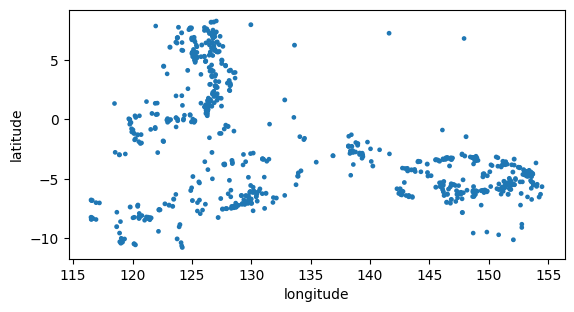

In [11]:
depth = df['depth']
long = df['longitude']
df.plot.scatter(x = 'longitude' , y = 'latitude', s = df['mag'])
plt.axis('scaled')

<Axes: xlabel='UTMX', ylabel='UTMY'>

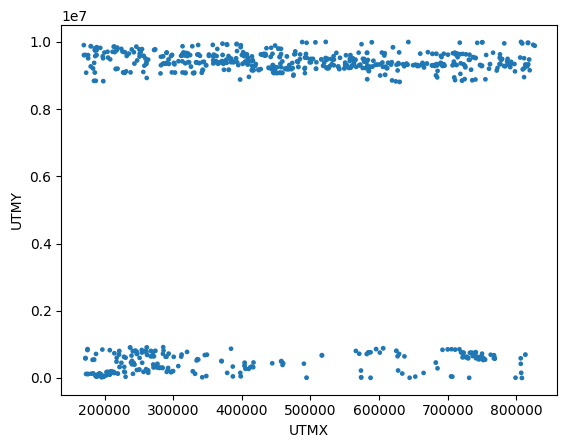

In [12]:
# depth = df['depth']
# long = df['longitude']
df.plot.scatter(x = 'UTMX' , y = 'UTMY', s = df['mag'])
# plt.axis('scaled')

The above is the result the fact that the area covers numerous UTM zones and also north an south of the equator. THIS PLOT SERVES AS A WARNING

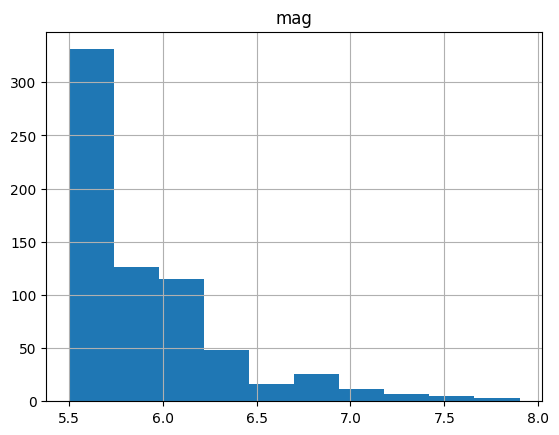

In [13]:
df.hist(column=["mag"])
plt.show()

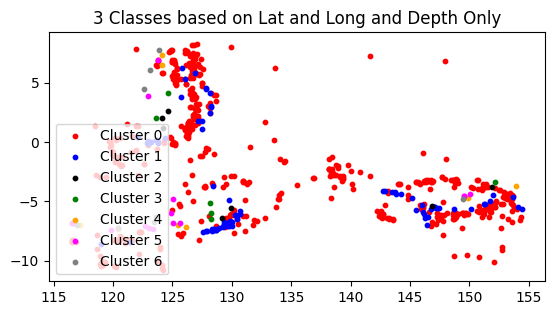

In [14]:
depth = df['depth']
lat = df['latitude']
Xaxis = df['longitude']

plt.scatter( long[depth<100],                  lat[depth<100],                   s=10, c='red',     label ='Cluster 0')
plt.scatter( long[(depth>=100) & (depth<200)], lat[(depth>=100) & (depth<200)],  s=10, c='blue',    label ='Cluster 1')
plt.scatter( long[(depth>=200) & (depth<300)], lat[(depth>=200) & (depth<300)],  s=10, c='black',   label ='Cluster 2')
plt.scatter( long[(depth>=300) & (depth<400)], lat[(depth>=300) & (depth<400)],  s=10, c='green',   label ='Cluster 3')
plt.scatter( long[(depth>=400) & (depth<500)], lat[(depth>=400) & (depth<500)],  s=10, c='orange',  label ='Cluster 4')
plt.scatter( long[(depth>=500) & (depth<600)], lat[(depth>=500) & (depth<600)],  s=10, c='magenta', label ='Cluster 5')
plt.scatter( long[(depth>=600) & (depth<700)], lat[(depth>=600) & (depth<700)],  s=10, c='grey',    label ='Cluster 6')
plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long and Depth Only')
plt.axis('scaled')
plt.show()

In [15]:
maxmag = df['mag'].max()
print('maxmag' , maxmag)
minmag = df['mag'].min()
print('minmag' , minmag)

maxdep = df['depth'].max()
print('maxdep' , maxdep)
mindep = df['depth'].min()
print('mindep' , mindep)

maxmag 7.9
minmag 5.5
maxdep 652.53
mindep 4.0


**The scatter plot below shows the latitudes and longitudes, with the marker size representing the magnitude and the colour representing the depth**  We scale the magnitudes to 20*(mag - min_mag)/(max_mag-min_mag)

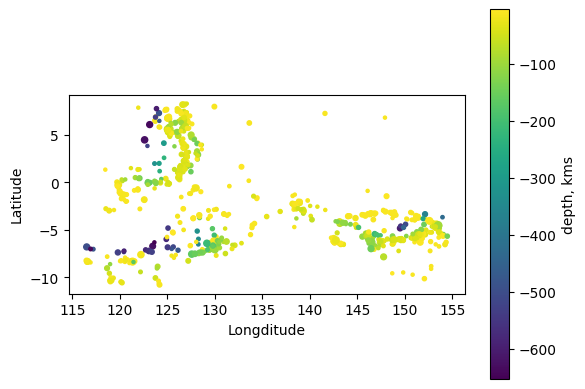

In [16]:
lat = df['latitude']
long = df['longitude']
depth = df['depth']
mag = df['mag']

s = 5 + 20*(mag - minmag)/(maxmag - minmag)
c = -depth

plt.scatter(long, lat, s=s, c=c )
plt.colorbar(label = 'depth, kms')
plt.xlabel('Longditude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.axis('scaled')
plt.show()

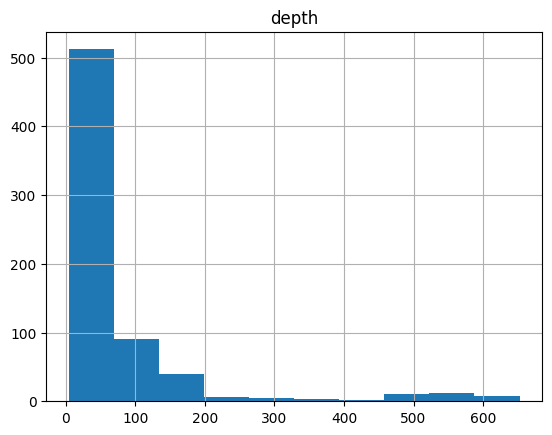

In [17]:
depth = -df['depth']
df.hist(column= ["depth"])
plt.show()

What can you say about the depths of the earthquakes?

**Now use the KMeans algorithm from scikit learn to cluster the eartquake locations according to their latitude and longitude.  How many clusters are appropriate?  Hint - look at the documentation for the dataset!**

In [18]:

# The random_state needs to be the same number to get reproducible results
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
y_km = kmeans.fit_predict(df[['latitude', 'longitude']])

kmeans.fit(df[['longitude', 'latitude']])
kmeans.labels_

print (y_km)


[0 1 2 0 0 1 2 0 0 2 2 2 2 2 0 2 1 2 2 2 2 2 2 2 2 1 1 1 1 1 0 1 1 2 1 0 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 2 0 1 2 0 1 1 1 1 1 1 1 1 1 1 2 0 0 1 1 2 1
 1 0 0 1 1 1 0 1 2 1 2 2 2 1 0 1 0 1 1 1 1 0 1 1 0 2 2 0 1 1 0 0 1 1 0 2 2
 1 0 2 2 1 1 0 0 2 1 0 1 1 1 1 0 0 1 2 2 2 2 1 0 2 1 1 0 0 2 1 0 0 0 1 1 2
 1 0 1 0 0 2 1 1 2 0 1 1 1 0 0 0 1 0 0 2 2 0 0 1 1 1 0 2 0 1 0 1 0 2 1 0 0
 1 2 0 1 0 0 1 1 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 1 0 0 0 0 0 0 1 0 0 0 1 2 0
 1 1 2 0 0 2 2 2 2 2 0 1 2 1 0 2 0 2 2 2 2 1 0 0 0 0 0 2 0 0 0 1 1 0 2 0 1
 2 2 1 0 1 1 1 1 1 1 1 2 0 1 1 1 0 0 1 0 0 0 0 0 1 2 1 0 1 2 0 1 0 0 2 0 2
 1 2 0 1 1 1 0 1 1 0 1 0 2 2 1 1 0 2 1 0 0 0 2 1 2 2 2 2 2 2 0 1 0 0 0 0 2
 1 2 2 2 1 1 0 0 1 1 1 1 2 1 1 0 0 0 0 1 1 1 2 2 1 1 0 1 1 1 0 0 0 0 1 0 2
 0 1 0 0 1 0 1 0 1 2 2 0 2 1 1 1 2 0 0 0 2 1 2 1 1 0 0 0 2 0 0 0 1 0 0 2 1
 2 0 1 2 1 2 2 0 1 1 2 2 1 0 1 1 2 2 0 0 2 1 0 1 1 0 2 0 2 1 1 1 0 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1 2 2 2 1 1 1 1 0 0 1 1 1 1 1 1 1 0 0 0 0 2 0
 0 2 2 1 1 0 0 0 0 0 1 0 

**Make a scatter plot showing the cluster each earthquake belongs to**

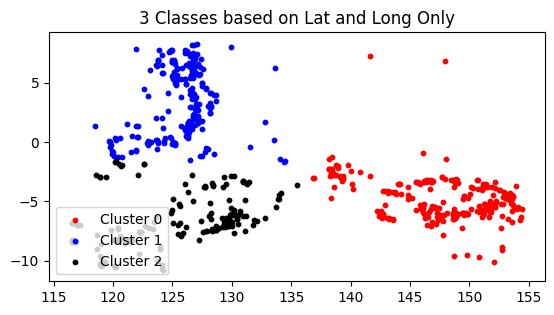

In [19]:
plt.scatter( long[y_km==0], lat[y_km==0], s=10, c='red',   label ='Cluster 0')
plt.scatter( long[y_km==1], lat[y_km==1], s=10, c='blue',  label ='Cluster 1')
plt.scatter( long[y_km==2], lat[y_km==2], s=10, c='black', label ='Cluster 2')
plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long Only')
plt.axis('scaled')
plt.show()

**Now perform KMeans clustering on the latitude, longitude and depth without scaling the inputs.  Plot the resulting clusters.  What do you notice?**

In [20]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
y_km = kmeans.fit_predict(df[['latitude', 'longitude', 'depth']])
#kmeans.fit(df[['lat', 'long']])
#kmeans.labels_
#print (y_km)

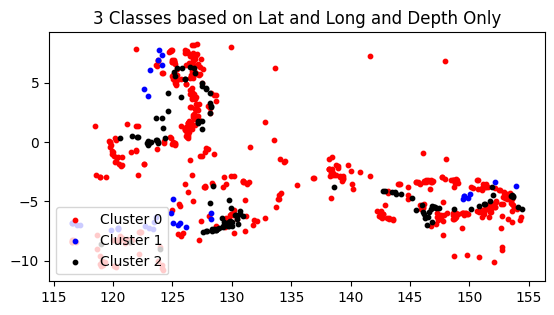

In [21]:
plt.scatter( long[y_km==0],  lat[y_km==0],  s=10, c='red',   label ='Cluster 0')
plt.scatter( long[y_km==1],  lat[y_km==1],  s=10, c='blue',  label ='Cluster 1')
plt.scatter( long[y_km==2],  lat[y_km==2],  s=10, c='black', label ='Cluster 2')
plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long and Depth Only')
plt.axis('scaled')
plt.show()

**Now perform clustering on the same three variables but this time normalize them (tip - use normalize from sklearn.preprocessing with axis=0).  Plot your results as lat vs long, long vs depth and lat vs depth.  What do you notice?**

In [22]:
normalizer_lat = Normalizer() #.fit(df)

df[['latNorm']] = (df[['latitude']] - df[['latitude']].min())/(df[['latitude']].max() - df[['latitude']].min())
df[['longNorm']] = (df[['longitude']] - df[['longitude']].min())/(df[['longitude']].max() - df[['longitude']].min())
df[['dpthNorm']] = (df[['depth']] - df[['depth']].min())/(df[['depth']].max() - df[['depth']].min())


<Axes: xlabel='longNorm', ylabel='latNorm'>

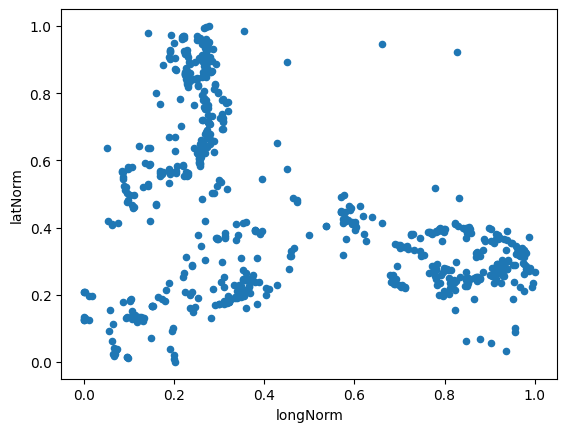

In [23]:
df.plot.scatter(x = 'longNorm', y = 'latNorm')


<Axes: xlabel='latNorm', ylabel='dpthNorm'>

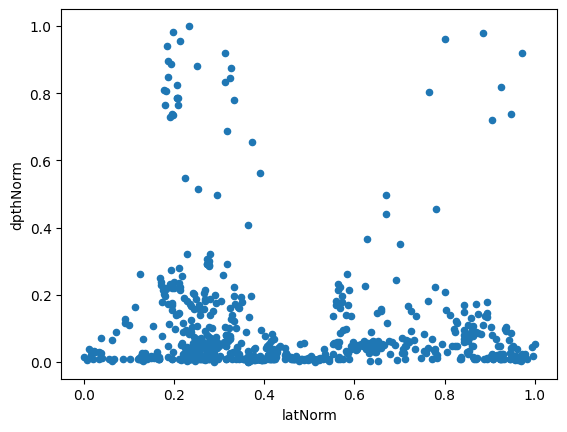

In [24]:
df.plot.scatter(x = 'latNorm', y = 'dpthNorm')


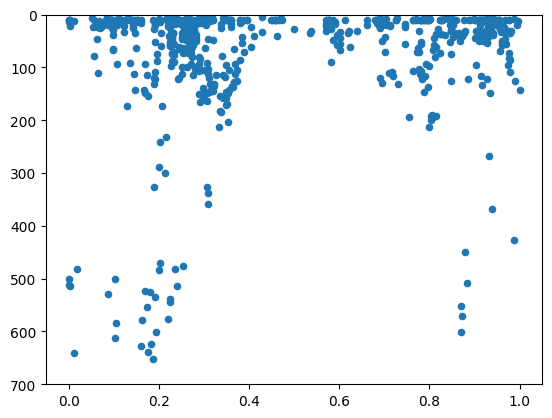

In [25]:
plt.scatter(x = df['longNorm'], y = df['depth'], marker = 'o', s=20)                   #'dpthNorm')
plt.ylim(700,0)
plt.show()


**Now make a scatter plot of the magnitutes against the number of stations.  Is there a correlation?  Does this make sense?**

In [26]:
x,y,z = df['latitude'], df['longitude'], df['depth']

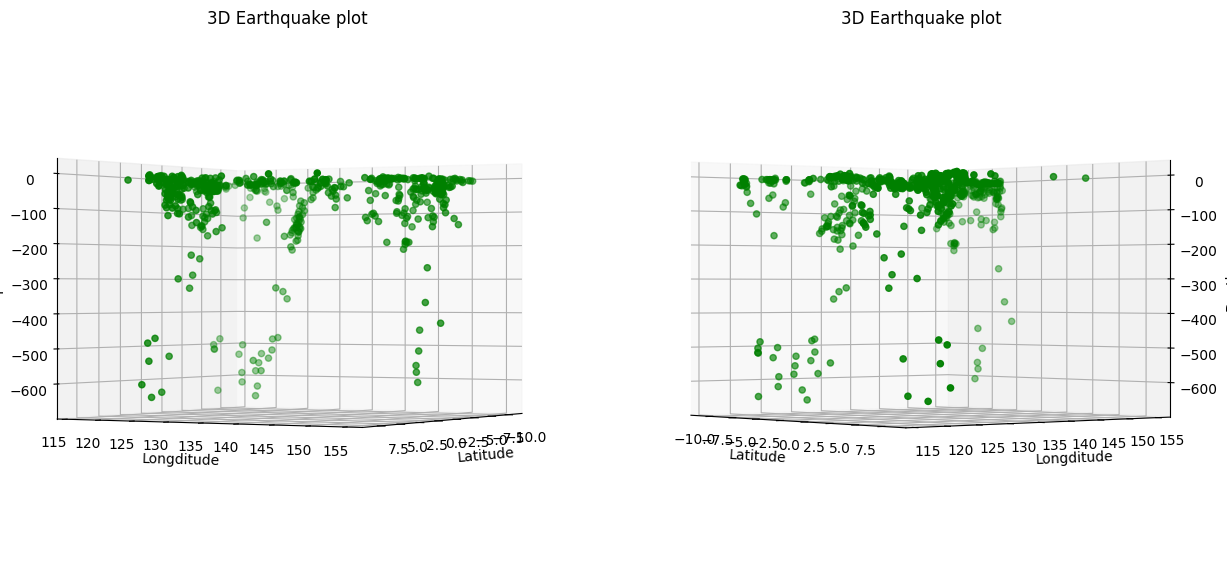

In [27]:
fig = plt.figure(figsize = (15,15))
ax = fig.add_subplot(1, 2, 1, projection='3d')

# load data for demonstration and plot a wireframe
ax.scatter3D(x, y, -z, color = "green", marker  = 'o')
#ax.plot_wireframe(X, Y, Z, rstride=5, cstride=5)
ax.set_xlabel("Latitude")
ax.set_ylabel("Longditude")
ax.set_zlabel("Depth")
plt.title("3D Earthquake plot")
ax.view_init(0, 30)

ax = fig.add_subplot(1, 2, 2, projection='3d')

# load data for demonstration and plot a wireframe
ax.scatter3D(x, y, -z, color = "green", marker  = 'o')
ax.set_xlabel("Latitude")
ax.set_ylabel("Longditude")
ax.set_zlabel("Depth")
plt.title("3D Earthquake plot")
ax.view_init(0, -40)

plt.show()

In [28]:

plotly_template = pio.templates["plotly"]
plotly_template.layout


px.scatter_3d( data_frame= df, x=df['longitude'], y=df['latitude'], z=-df['depth'], color=df['mag'], symbol=None, size=df['mag'],
                          text=None, hover_name=None, hover_data=None, custom_data=None, error_x=None,
                          error_x_minus=None, error_y=None, error_y_minus=None, error_z=None, error_z_minus=None,
                          animation_frame=None, animation_group=None, category_orders=None, labels=None, size_max=None,
                          color_discrete_sequence=None, color_discrete_map=None, color_continuous_scale=px.colors.sequential.Rainbow, range_color=None,
                          color_continuous_midpoint=None, symbol_sequence=None, symbol_map=None, opacity=None, log_x=False, log_y=False, log_z=False,
                          range_x=None, range_y=None, range_z=None, title='3d View of Earthquakes', template=None, width=None, height=None)


# fig.update_layout(legend_orientation="h",margin=dict(l=0, r=0, b=0, t=0))
# fig.show()


In [29]:
fig = px.scatter_3d(
    data_frame=df,
    x='latitude',
    y='longitude',
    z=-df['depth'],
    color='mag',
    size='mag',
    color_continuous_scale=px.colors.sequential.Rainbow,
    title='3D View of Earthquakes (Equal X-Y Scaling)'
)

# Calculate the actual data ranges to make X and Y scaling equal
lat_range = df['latitude'].max() - df['latitude'].min()
lon_range = df['longitude'].max() - df['longitude'].min()

# Adjust aspectratio dynamically so X and Y are proportional (1:1 spatial aspect)
# We set a custom z-scale ratio (e.g., 0.5) so the depth axis is not overly stretched
fig.update_layout(
    scene=dict(
        aspectmode='manual',
        aspectratio=dict(
            x=1.0,
            y=lon_range / lat_range,
            z=0.5
        )
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()